# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import os
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj
    %cd /content/proj
    # Pin statsforecast to the exact version autogluon.timeseries resolves to,
    # so installing AutoGluon in section 3 cannot swap it under the running kernel.
    !pip install -q -e . "statsforecast==2.0.3"

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()
warnings.filterwarnings("ignore", category=FutureWarning)
os.makedirs("figures", exist_ok=True)   # charts reused in report.md

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report
N_WINDOWS = 8     # rolling origins in the harness

---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [2]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [3]:
# Confirm the calendar: how many months, what range, any gaps?
n_obs = len(df)
range_ = (df["ds"].min(), df["ds"].max())
expected = pd.date_range(range_[0], range_[1], freq="MS")
n_gaps = len(expected.difference(df["ds"]))
assert not df["ds"].duplicated().any(), "duplicate months"
assert df["y"].notna().all(), "missing values"
print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

144 months, 1949-01-01 to 1960-12-01, 0 gaps


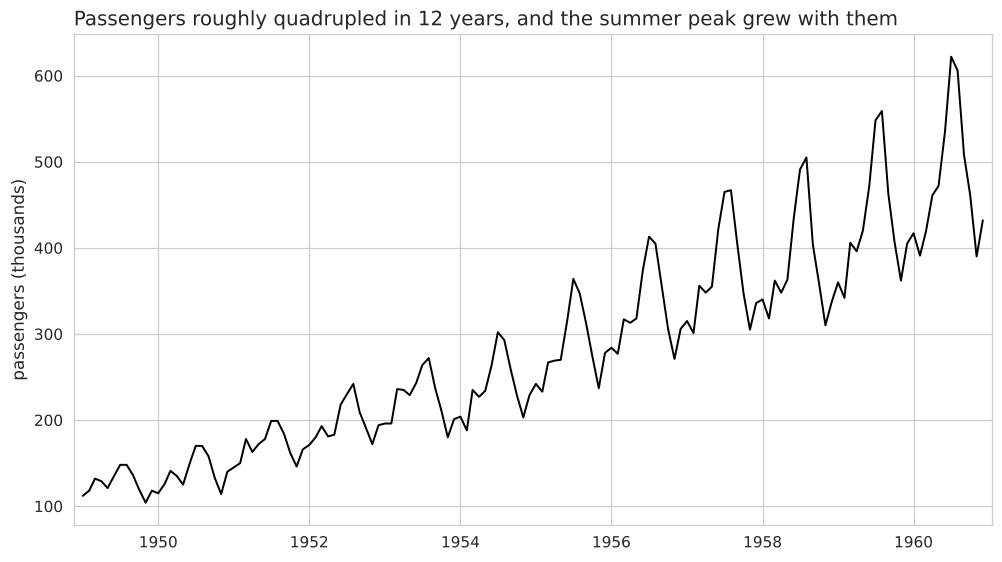

yearly mean: 127 (1949) -> 476 (1960)
peak-to-trough swing within the year: 44 (1949) -> 232 (1960)
swing as a share of the yearly mean: 35% (1949) -> 49% (1960)


In [4]:
ax = P.plot_series(df, title="Passengers roughly quadrupled in 12 years, "
                   "and the summer peak grew with them",
                   ylabel="passengers (thousands)", xlabel="")
plt.savefig("figures/01_series.png", bbox_inches="tight")
plt.show()

by_year = df.groupby(df["ds"].dt.year)["y"]
swing = (by_year.max() - by_year.min())
print(f"yearly mean: {by_year.mean().iloc[0]:.0f} (1949) -> {by_year.mean().iloc[-1]:.0f} (1960)")
print(f"peak-to-trough swing within the year: {swing.iloc[0]:.0f} (1949) -> {swing.iloc[-1]:.0f} (1960)")
print(f"swing as a share of the yearly mean: "
      f"{(swing / by_year.mean()).iloc[0]:.0%} (1949) -> {(swing / by_year.mean()).iloc[-1]:.0%} (1960)")

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

**My read.** Air travel grew steadily, from about 127 thousand passengers a
month in 1949 to about 476 thousand in 1960, and every year has the same
rhythm: a summer peak in July-August and a low in November. As traffic grew,
the summer peak grew with it (the gap between the busiest and quietest month
went from 44 to 232 thousand), so the swings are proportional to the level,
not a fixed size; there is no multi-year boom-and-bust cycle, only the odd
flat year such as 1958.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

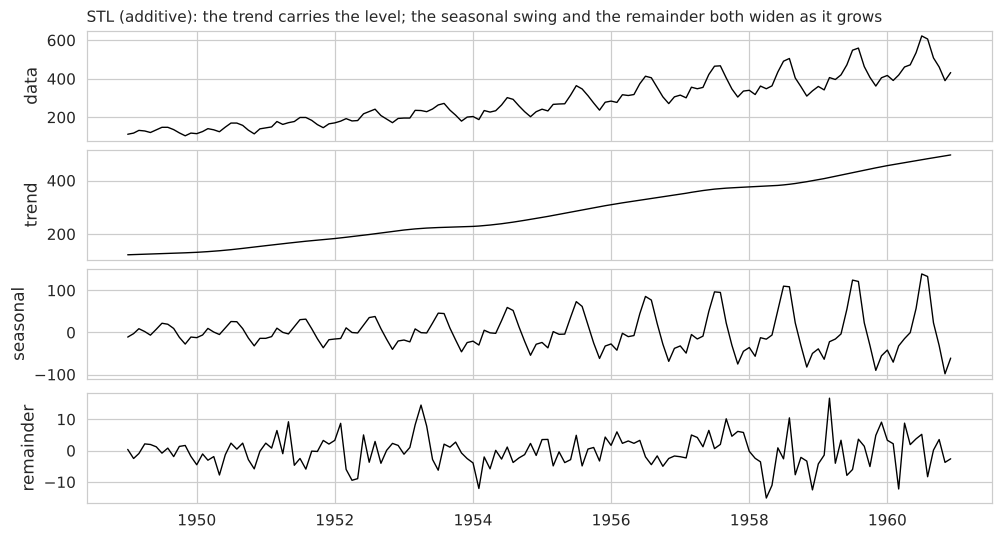

trend: 123 -> 496
seasonal amplitude: 50 (1949) -> 237 (1960)
remainder SD: 3.3 (first 3 years) -> 6.9 (last 3 years)


In [5]:
from statsmodels.tsa.seasonal import STL

# Exploration only: STL sees the whole series. Nothing from it feeds a model
# or a score, so this is not leakage into the harness.
stl = STL(df.set_index("ds")["y"], period=SEASON_LENGTH).fit()
dcmp = pd.DataFrame({
    "ds": df["ds"],
    "data": df["y"].to_numpy(),
    "trend": stl.trend.to_numpy(),
    "seasonal": stl.seasonal.to_numpy(),
    "remainder": stl.resid.to_numpy(),
})
P.decomposition_plot(dcmp, cols=["data", "trend", "seasonal", "remainder"],
                     title="STL (additive): the trend carries the level; the "
                           "seasonal swing and the remainder both widen as it grows",
                     x="ds")
plt.show()

seas_amp = dcmp.groupby(dcmp["ds"].dt.year)["seasonal"].agg(lambda s: s.max() - s.min())
print(f"trend: {dcmp.trend.min():.0f} -> {dcmp.trend.max():.0f}")
print(f"seasonal amplitude: {seas_amp.iloc[0]:.0f} (1949) -> {seas_amp.iloc[-1]:.0f} (1960)")
print(f"remainder SD: {dcmp.remainder.iloc[:36].std():.1f} (first 3 years) -> "
      f"{dcmp.remainder.iloc[-36:].std():.1f} (last 3 years)")

**Reading the panels.** The **trend** does the work: it carries the series
from 123 to 496 thousand, smooth and almost straight, and it is most of the
variance. The **seasonal** panel is the same summer-peak shape every year, but
its height grows from 50 to 237 thousand: an *additive* STL has to let the
seasonal component widen because the real seasonality is *multiplicative*
(proportional to the level). The **remainder** is small and patternless, but
it also widens (SD 3.3 → 6.9), which is the same multiplicative signature
leaking through. A log transform would steady both.

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [6]:
# Textbook (FPP3) formulas on the STL components:
#   F_T = max(0, 1 - Var(R) / Var(T + R))
#   F_S = max(0, 1 - Var(R) / Var(S + R))
R, T, S = dcmp["remainder"], dcmp["trend"], dcmp["seasonal"]
trend_strength = max(0.0, 1 - R.var() / (T + R).var())
seasonal_strength = max(0.0, 1 - R.var() / (S + R).var())
print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.99


**What the strengths imply.** Both are at the top of the [0, 1] scale
(trend 1.00, seasonal 0.99): this series is almost entirely trend plus
season with very little noise. Any model worth shipping must carry **both** a
trend and a seasonal component. The seasonal naive carries only the season,
so it will lag the growth every year; the plain naive and the drift carry
only a level or a trend, so they will miss the season. The candidates are
models with both: seasonal ARIMA (with differencing), ETS with trend and
seasonal terms, or Theta on a deseasonalised series.

**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

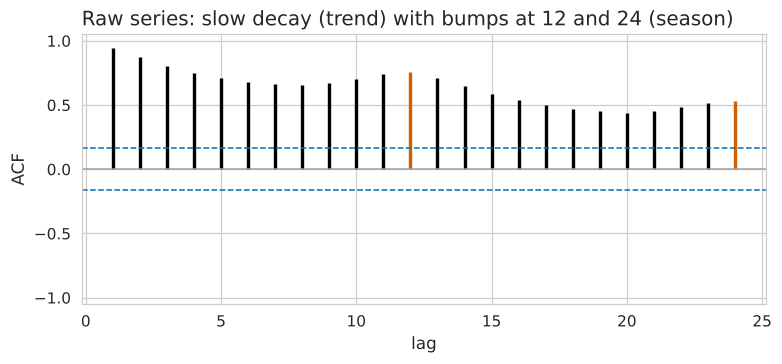

r1 = 0.95, r6 = 0.68, r12 = 0.76, r24 = 0.53  (significance bound +/-0.16)


In [7]:
r, bound = P.acf_values(df["y"], nlags=24)
P.acf_plot(df["y"], nlags=24, highlight_every=SEASON_LENGTH, figsize=(7, 3.2),
           title="Raw series: slow decay (trend) with bumps at 12 and 24 (season)")
plt.show()
print(f"r1 = {r[0]:.2f}, r6 = {r[5]:.2f}, r12 = {r[11]:.2f}, r24 = {r[23]:.2f}  "
      f"(significance bound +/-{bound:.2f})")

**Reading the ACF.** Lag 1 is 0.95 and the bars decay slowly: that slow
decay is the trend (this month looks like last month because both are high
up the same slope). On top of the decay there are bumps at 12 (0.76) and 24
(0.53), higher than the lags around them: that is the season - July looks
like the July before. **In one sentence a non-forecaster could repeat:**
*this month's traffic is best predicted by last month and by the same month
last year, because traffic is climbing and every year has the same summer
peak.*

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,447.564102,463.5405,488.177552
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,421.564102,437.5405,462.177552
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,449.564102,465.5405,490.177552
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,491.564102,507.5405,532.177552
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,502.564102,518.5405,543.177552


In [9]:
from statsforecast.models import Naive, RandomWalkWithDrift

# Two more benchmarks: the plain naive (last value carried forward) and the
# random walk with drift (last value plus the average monthly change).
bench_sf = StatsForecast(models=[Naive(), RandomWalkWithDrift()],
                         freq="MS", n_jobs=1)
bench_fc = bench_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
bench_fc[["ds", "Naive", "RWD"]].head(3)

,ds,Naive,RWD
0,1961-01-01,432.0,434.237762
1,1961-02-01,432.0,436.475524
2,1961-03-01,432.0,438.713287


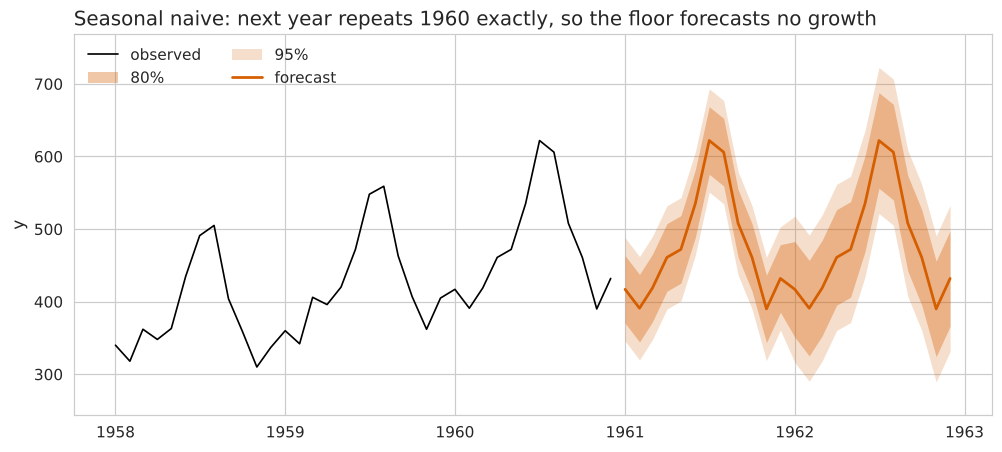

In [10]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive: next year repeats 1960 exactly, so the floor forecasts no growth",
            history_tail=36, levels=(80, 95))
plt.show()

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

/tmp/ipykernel_508/3031699725.py:10: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


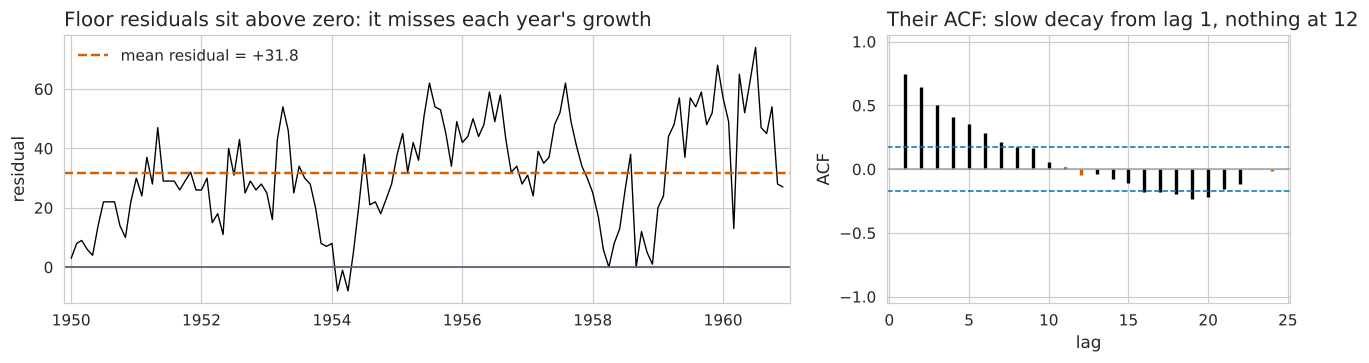

mean residual: +31.8   r1 = 0.75, r2 = 0.65, r3 = 0.50, r12 = -0.04  (bound +/-0.17)
mean residual by year (= that year's growth over the last):
{1950: 13.0, 1951: 30.5, 1952: 26.8, 1953: 28.0, 1954: 13.9, 1955: 45.1, 1956: 44.2, 1957: 40.2, 1958: 12.6, 1959: 47.3, 1960: 47.8}


In [11]:
resid_floor = (df["y"] - df["y"].shift(SEASON_LENGTH)).rename("resid")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4),
                         gridspec_kw={"width_ratios": [1.8, 1]})
P.residual_time_plot(resid_floor, ds=df["ds"], ax=axes[0], show_mean=True,
                     title="Floor residuals sit above zero: it misses each year's growth")
P.acf_plot(resid_floor.dropna(), nlags=24, ax=axes[1],
           highlight_every=SEASON_LENGTH,
           title="Their ACF: slow decay from lag 1, nothing at 12")
plt.tight_layout()
plt.show()

rf, bf = P.acf_values(resid_floor.dropna(), nlags=24)
print(f"mean residual: {resid_floor.mean():+.1f}   "
      f"r1 = {rf[0]:.2f}, r2 = {rf[1]:.2f}, r3 = {rf[2]:.2f}, r12 = {rf[11]:.2f}  "
      f"(bound +/-{bf:.2f})")
print("mean residual by year (= that year's growth over the last):")
print(resid_floor.groupby(df["ds"].dt.year).mean().dropna().round(1).to_dict())

**What the floor leaves on the table.** The residual plot sits clearly above
zero (mean +31.8 thousand): the floor repeats last year, so every year it
misses that year's growth. The mean residual by year *is* the growth, and it
is not constant (13 in 1950 and 1958, 45-48 in the fast years), so it is a
wandering trend, not a fixed one.

The ACF says the same thing in a different language: a slow decay from lag
1 (0.75, 0.65, 0.50 ...) - a residual that stays high for months once it is
high - and **nothing at 12** (-0.04). So the season is fully eaten by the
floor; what is left is the **trend/growth with short-term memory**. That is
the structure a model with a differenced trend plus autoregressive terms eats
(seasonal ARIMA: a seasonal difference plus a first difference and an AR
term), or ETS with a trend component. The second benchmarks show the
other half: the naive and the drift carry the level but not the season.

**2.2 An honest interval for the floor.** A band is only honest if it
covers what it says. The floor's band is built from its own residuals; the
check is how often the actual months land inside it over the harness folds
(the same 8 origins section 4 uses).

In [12]:
# The floor through the harness (section 4 re-uses the same folds): 8 origins,
# 12 months each, every fold fitted only on the data before its cutoff.
floor_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)], freq="MS", n_jobs=1
).cross_validation(df=df, h=H, step_size=H, n_windows=N_WINDOWS,
                   level=scoring.LEVELS)

m = "SeasonalNaive"
lo, hi = floor_cv[f"{m}-lo-80"], floor_cv[f"{m}-hi-80"]
print(f"80% band, average width: {(hi - lo).mean():.0f} thousand "
      f"({((hi - lo) / floor_cv[m]).mean():.0%} of the forecast)")
print(f"80% coverage: {scoring.coverage(floor_cv, m, 80):.0%} (nominal 80%)   "
      f"95% coverage: {scoring.coverage(floor_cv, m, 95):.0%} (nominal 95%)")
print(f"misses above the band: {(floor_cv.y > hi).mean():.0%}   "
      f"misses below: {(floor_cv.y < lo).mean():.0%}")

80% band, average width: 78 thousand (27% of the forecast)
80% coverage: 51% (nominal 80%)   95% coverage: 93% (nominal 95%)
misses above the band: 49%   misses below: 0%


**Verdict on the floor's band.** The 80% band is 78 thousand wide on
average (27% of the forecast) but it covers only **51%** of months, against a
nominal 80%. The misses are one-sided: 49% above, 0% below. The band is not
just too narrow, it is *in the wrong place* - centred on last year when the
series has moved up. The 95% band (93%) looks nearly honest only because it
is wide enough to swallow the bias. So the floor's interval is dishonest at
80%, and the reason is the same growth its residuals showed.

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [13]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG and "google.colab" in sys.modules:
    print("Installing autogluon.timeseries (a few minutes) ...")
    !pip install -q 'autogluon.timeseries' "statsforecast==2.0.3"
    importlib.invalidate_caches()
    HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

# Guard: the statsforecast on disk must still be the one this kernel loaded.
from importlib.metadata import version as _version
import statsforecast as _sfm
_loaded = getattr(_sfm, "__version__", None)
_disk = _version("statsforecast")
if _loaded and _loaded != _disk:
    raise RuntimeError(f"statsforecast changed from {_loaded} to {_disk} during the session. "
                       "Runtime -> Restart session, then Run all.")
print(f"statsforecast {_disk}")

autogluon is available
statsforecast 2.0.3


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [14]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    #   unique_id -> item_id, ds -> timestamp, y stays y (named via target="y").
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects: the fit never sees 1960.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows "
          f"(ends {ag_train.index.get_level_values('timestamp').max().date()})")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows (ends 1959-12-01)


In [15]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [16]:
if HAS_AG:
    # score_test: the 12 held-out months (1960), never seen by the fit.
    # score_val:  AutoGluon's own internal validation on the end of ag_train.
    lb = predictor.leaderboard(tsdf)
    display(lb[["model", "score_val", "score_test", "fit_order"]])

    trainer = getattr(predictor, "_learner", None)
    trainer = getattr(trainer, "trainer", None)
    n_val = getattr(trainer, "num_val_windows", None)
    if isinstance(n_val, (tuple, list)):
        n_val = n_val[0]
    n_val = n_val if n_val is not None else "1 (default)"
    print(f"validation windows behind score_val: {n_val}   "
          f"each {predictor.prediction_length} months, the last year of ag_train (1959)")
    print(f"sign of score_val: always <= 0 here "
          f"(min {lb.score_val.min():.3f}, max {lb.score_val.max():.3f}) - "
          "AutoGluon reports -MASE so that higher is better")
    print("\nranked by score_val (what AutoGluon chose by):")
    print(lb.sort_values("score_val", ascending=False)[["model", "score_val"]]
          .to_string(index=False))
    print(f"\nmodel_best: {predictor.model_best}")

,model,score_val,score_test,fit_order
0,AutoARIMA,-1.575987,-0.608073,5
1,Theta,-1.633923,-0.875371,3
2,WeightedEnsemble,-1.535792,-0.929514,6
3,AutoETS,-1.554323,-1.169539,4
4,SeasonalNaive,-1.656513,-1.570881,2
5,Naive,-3.196371,-2.495895,1


validation windows behind score_val: 1   each 12 months, the last year of ag_train (1959)
sign of score_val: always <= 0 here (min -3.196, max -1.536) - AutoGluon reports -MASE so that higher is better

ranked by score_val (what AutoGluon chose by):
           model  score_val
WeightedEnsemble  -1.535792
         AutoETS  -1.554323
       AutoARIMA  -1.575987
           Theta  -1.633923
   SeasonalNaive  -1.656513
           Naive  -3.196371

model_best: WeightedEnsemble


**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

**My read.**

- **Sign.** Every `score_val` is negative (-1.54 to -3.20). AutoGluon
  reports `-MASE` so that "higher is better" holds for every metric; the best
  model has the score *closest to zero*. A MASE of 1.54 on that window means
  every model, the ensemble included, did worse than a one-year-ago forecast
  scaled on the training history.
- **What it fitted.** Five local models (Naive, SeasonalNaive, AutoETS,
  AutoARIMA, Theta) plus a `WeightedEnsemble` it built from them.
- **How many windows.** **One.** `score_val` comes from a single internal
  validation window, the last 12 months of `ag_train` (1959). `score_test`
  is one more single window (1960).
- **What the ranking can and cannot be trusted to do.** It can be trusted to
  shortlist: the four models with trend + season all beat the floor and the
  plain naive, which agrees with section 1. It cannot be trusted to *order*
  that shortlist: on 1959 the ensemble, AutoETS and AutoARIMA sit within
  0.04 MASE of each other on 12 points, and on 1960 the order flips
  (AutoARIMA 0.61, Theta 0.88, ETS 1.17). One year is one draw; a different
  year gives a different winner.
- **Shortlist carried forward:** the three single models with trend + season
  - AutoARIMA, AutoETS, Theta (statsforecast twin: AutoTheta). The
  ensemble has no statsforecast twin; it is a blend of these three, so if no
  single member wins clearly in the harness, an ensemble is the next thing to
  test. None of these numbers is used as evidence below.

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [17]:
# The floor plus the two other benchmarks, over the same 8 rolling origins.
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH), Naive(), RandomWalkWithDrift()],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=N_WINDOWS,
                            level=scoring.LEVELS)
print("cutoffs:", [c.date().isoformat() for c in cv["cutoff"].unique()])
cv.head()

cutoffs: ['1952-12-01', '1953-12-01', '1954-12-01', '1955-12-01', '1956-12-01', '1957-12-01', '1958-12-01', '1959-12-01']


,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,...,RWD-lo-20,RWD-lo-40,RWD-lo-60,RWD-lo-80,RWD-lo-95,RWD-hi-20,RWD-hi-40,RWD-hi-60,RWD-hi-80,RWD-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,...,191.675742,187.322426,182.227631,175.162029,164.266231,199.813620,204.166935,209.261731,216.327333,227.223131
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,...,191.675381,185.455063,178.175267,168.079448,152.510780,203.303343,209.523660,216.803456,226.899275,242.467943
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,...,192.041107,184.345460,175.339048,162.848711,143.587479,206.426979,214.122625,223.129037,235.619375,254.880606
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,...,192.590391,183.615801,173.112610,158.546499,136.084237,209.367056,218.341646,228.844836,243.410948,265.873210
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,...,193.253464,183.121674,171.264182,154.819889,129.461299,212.193345,222.325135,234.182627,250.626920,275.985509


In [18]:
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta

# The leaderboard's shortlist, as statsforecast twins. AutoARIMA is the model
# carried forward; AutoETS and AutoTheta go through the same folds so the
# harness can confirm or move the leaderboard's order.
MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)   # statsforecast class instance
MY_NAME  = "AutoARIMA"                              # its output column name
OTHERS   = [AutoETS(season_length=SEASON_LENGTH), AutoTheta(season_length=SEASON_LENGTH)]

mysf = StatsForecast(models=[MY_MODEL, *OTHERS], freq="MS", n_jobs=1)
mycv = mysf.cross_validation(df=df, h=H, step_size=H, n_windows=N_WINDOWS,
                             level=scoring.LEVELS)
assert (mycv["cutoff"].unique() == cv["cutoff"].unique()).all(), "folds differ"

# One frame, every model, same folds; each fold's MASE/RMSSE denominator comes
# from that fold's own history only (scoring.score_cv).
allcv = cv.merge(mycv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
MODELS = ["SeasonalNaive", "Naive", "RWD", "AutoETS", "AutoTheta", MY_NAME]

rows = {}
for m in MODELS:
    s = scoring.score_cv(allcv, m, df)
    lo, hi = allcv[f"{m}-lo-80"], allcv[f"{m}-hi-80"]
    s["coverage_95"] = scoring.coverage(allcv, m, 95)
    s["width_80_pct"] = float(((hi - lo) / allcv[m]).mean())
    s["mean_error"] = float((allcv["y"] - allcv[m]).mean())
    rows[m] = s
RESULTS = (pd.DataFrame(rows).T[["mase", "rmsse", "crps", "coverage_80",
                                  "coverage_95", "width_80_pct", "mean_error",
                                  "mase_min", "mase_max"]]
           .rename_axis("model"))
RESULTS.round(3)

,mase,rmsse,crps,coverage_80,coverage_95,width_80_pct,mean_error,mase_min,mase_max
model,,,,,,,,,
SeasonalNaive,1.313,1.246,0.062,0.510,0.927,0.269,34.896,0.412,1.959
Naive,2.119,2.452,0.110,0.688,0.854,0.504,55.510,1.422,3.196
RWD,1.813,2.156,0.095,0.760,0.896,0.499,43.190,1.187,2.766
AutoETS,0.952,1.003,0.050,0.490,0.708,0.151,20.168,0.565,1.554
AutoTheta,0.898,0.988,0.046,0.594,0.760,0.217,17.280,0.451,1.405
AutoARIMA,0.647,0.683,0.034,0.698,0.844,0.134,5.878,0.330,1.594


floor       AutoARIMA      
               MASE cov80      MASE cov80
forecast year                            
1953           1.19  0.67      0.44  0.75
1954           0.68  0.92      0.39  0.83
1955           1.96  0.08      0.77  0.50
1956           1.66  0.25      0.33  1.00
1957           1.38  0.67      0.41  0.92
1958           0.41  1.00      0.64  0.75
1959           1.66  0.25      1.59  0.00
1960           1.57  0.25      0.61  0.83

AutoARIMA beats the floor on MASE in 7 of 8 years


/tmp/ipykernel_508/2036890117.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


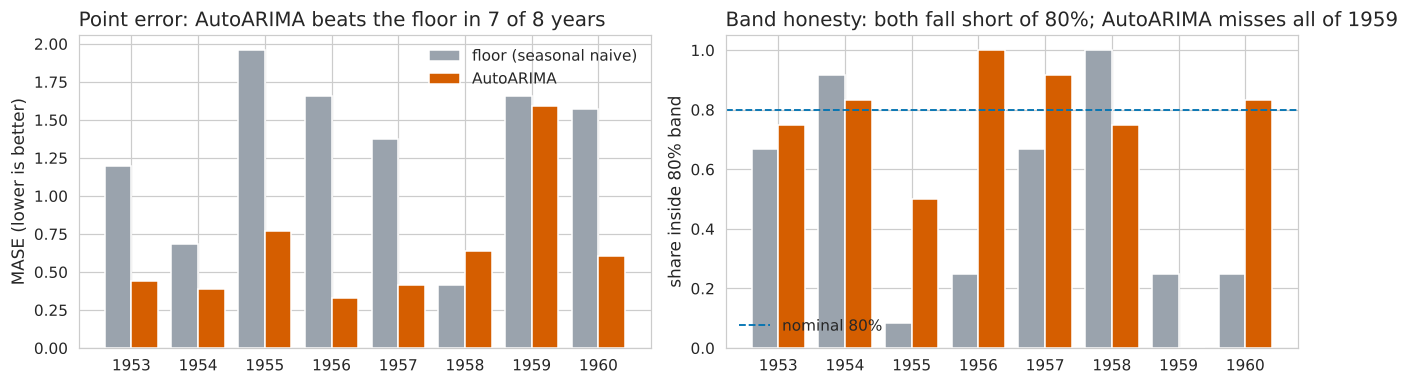

In [19]:
from utilsforecast.losses import mase as _mase

def fold_table(model):
    out = []
    for cut, g in allcv.groupby("cutoff"):
        hist = df[df["ds"] <= cut]
        sc = g.drop(columns="cutoff")
        out.append({
            "forecast year": cut.year + 1,
            "MASE": float(_mase(sc, models=[model], seasonality=SEASON_LENGTH,
                                train_df=hist)[model].iloc[0]),
            "cov80": scoring.coverage(g, model, 80),
        })
    return pd.DataFrame(out).set_index("forecast year")

PER_FOLD = pd.concat({"floor": fold_table("SeasonalNaive"),
                      MY_NAME: fold_table(MY_NAME)}, axis=1)
display(PER_FOLD.round(2))
wins = (PER_FOLD[(MY_NAME, "MASE")] < PER_FOLD[("floor", "MASE")]).sum()
print(f"{MY_NAME} beats the floor on MASE in {wins} of {len(PER_FOLD)} years")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
yrs = PER_FOLD.index.astype(str)
x = np.arange(len(yrs))
axes[0].bar(x - 0.2, PER_FOLD[("floor", "MASE")], 0.4, color=P.GREY, label="floor (seasonal naive)")
axes[0].bar(x + 0.2, PER_FOLD[(MY_NAME, "MASE")], 0.4, color=P.ORANGE, label=MY_NAME)
axes[0].set(xticks=x, xticklabels=yrs, ylabel="MASE (lower is better)",
            title=f"Point error: {MY_NAME} beats the floor in {wins} of 8 years")
axes[0].legend(frameon=False)
axes[1].bar(x - 0.2, PER_FOLD[("floor", "cov80")], 0.4, color=P.GREY)
axes[1].bar(x + 0.2, PER_FOLD[(MY_NAME, "cov80")], 0.4, color=P.ORANGE)
axes[1].axhline(0.8, color=P.BLUE, ls="--", lw=1.2, label="nominal 80%")
axes[1].set(xticks=x, xticklabels=yrs, ylim=(0, 1.05), ylabel="share inside 80% band",
            title="Band honesty: both fall short of 80%; AutoARIMA misses all of 1959")
axes[1].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig("figures/02_harness.png", bbox_inches="tight")
plt.show()

/tmp/ipykernel_508/218239092.py:17: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


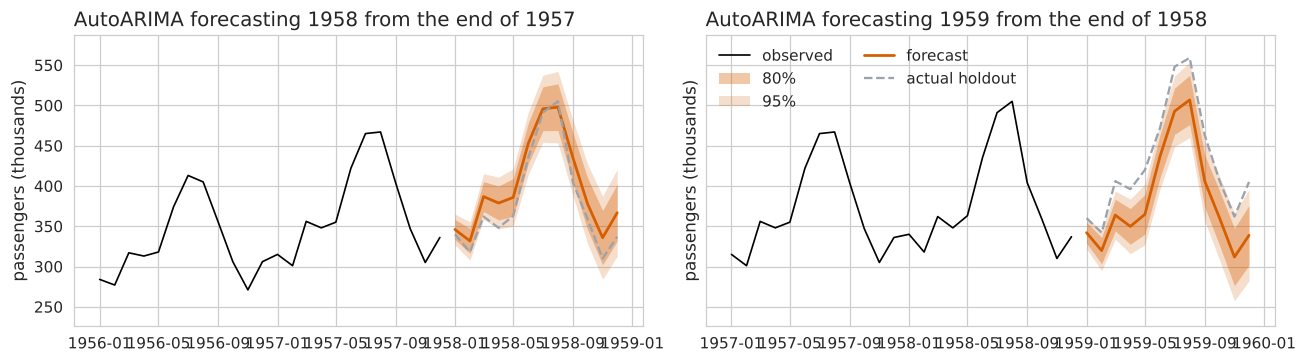

In [20]:
# The two years that break the pattern: 1958 (growth stalls) and 1959 (it comes back).
fans = []
for yr in (1958, 1959):
    g = allcv[allcv["ds"].dt.year == yr]
    fans.append(g.rename(columns={MY_NAME: "mean", f"{MY_NAME}-lo-80": "lo-80",
                                  f"{MY_NAME}-hi-80": "hi-80",
                                  f"{MY_NAME}-lo-95": "lo-95",
                                  f"{MY_NAME}-hi-95": "hi-95"}))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, f, yr in zip(axes, fans, (1958, 1959)):
    hist = df[df["ds"] < f["ds"].min()]
    P.fan_chart(hist, f, ax=ax, history_tail=24, levels=(80, 95),
                actual=f[["ds", "y"]],
                title=f"{MY_NAME} forecasting {yr} from the end of {yr - 1}")
    ax.set_ylabel("passengers (thousands)")
axes[0].legend().remove() if axes[0].get_legend() else None
plt.tight_layout()
plt.show()

**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

**My read.**

- **The harness moves the leaderboard.** AutoGluon's internal split put
  AutoETS ahead of AutoARIMA; over eight years the order is AutoARIMA (MASE
  0.65), AutoTheta (0.90), AutoETS (0.95). One window could not tell them
  apart; eight can.
- **AutoARIMA vs the floor:** wins on all three metrics - MASE 0.65 vs 1.31
  (half the point error), scaled CRPS 0.034 vs 0.062 (the whole distribution
  is better, not just the centre), and 80% coverage 70% vs 51%. It beats the
  floor in 7 of 8 years; it **loses in 1958** (0.64 vs 0.41), the year growth
  stalled and repeating last year happened to be right. It is also nearly
  unbiased out of sample (mean error +5.9 vs +34.9).
- **AutoETS and AutoTheta vs the floor:** both win on the point (0.95, 0.90)
  and on CRPS (0.050, 0.046), but **neither wins on the band**: AutoETS
  covers 49% at 80% (no better than the floor's 51%, and its 95% band covers
  only 71%), AutoTheta 59%. AutoETS selected a model with *no trend*
  (ETS(M,N,M)), so it under-forecasts every year (mean error +20) inside a
  narrow band. A point win with a dishonest band: both halves reported.
- **Coverage verdict.** No model is honest at 80%. AutoARIMA is the closest
  (70%, and 84% at 95%) and its misses are concentrated: in 1959 it covered
  **0 of 12 months** - it was fitted at the end of the flat year 1958,
  forecast flat-ish growth, and the series jumped back. Leave 1959 out and its
  other seven years average about 80%. The band is roughly honest in ordinary years
  and too narrow after a shock; the residuals below show why it is narrow
  in the late, high-traffic years.
- **The drift and naive** carry the growth but not the season; their wide
  bands (50% of the forecast) buy coverage (69-76%) at a far worse CRPS. Wide
  is not the same as honest.

---
**4.2 What the chosen model misses.** The harness picks the model; the
residuals say what it still gets wrong.

selected on the full series: ARIMA(1,1,0)(0,1,0)[12]
for comparison, AutoETS selects: ETS(M,N,M) (error, trend, season) - N = no trend


/tmp/ipykernel_508/2442770398.py:24: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


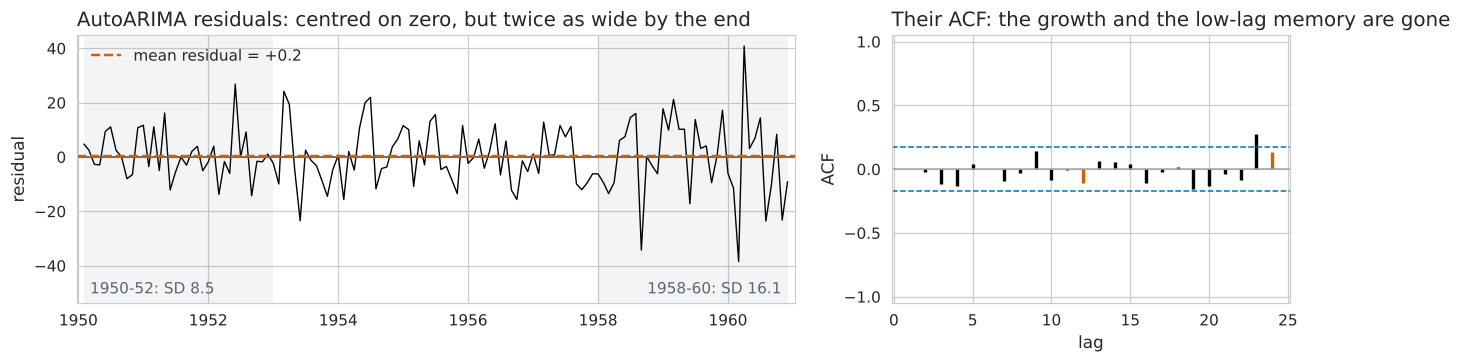

mean residual +0.24; lags outside +/-0.17: [23] (values [0.28])
8 largest |residuals| fall in months: ['Apr', 'Aug', 'Jun', 'Jun', 'Mar', 'Mar', 'Nov', 'Sep']
out-of-sample mean error (actual - forecast), harness: +5.9 vs floor +34.9


In [21]:
# The chosen model on the full series: what order it picks, and what its
# in-sample residuals leave behind.
from statsforecast.arima import arima_string

final_sf = StatsForecast(models=[AutoARIMA(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
final_fc = final_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS, fitted=True)
fitted = final_sf.forecast_fitted_values()
order = StatsForecast(models=[AutoARIMA(season_length=SEASON_LENGTH)], freq="MS").fit(df)
print("selected on the full series:", arima_string(order.fitted_[0, 0].model_).strip())
ets_full = StatsForecast(models=[AutoETS(season_length=SEASON_LENGTH)], freq="MS").fit(df)
print("for comparison, AutoETS selects:", ets_full.fitted_[0, 0].model_["method"],
      "(error, trend, season) - N = no trend")

resid_my = (fitted["y"] - fitted[MY_NAME]).iloc[SEASON_LENGTH + 1:]   # skip differencing warm-up
ds_my = fitted["ds"].iloc[SEASON_LENGTH + 1:]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.8, 1]})
P.residual_time_plot(resid_my, ds=ds_my, ax=axes[0], show_mean=True, era_months=36,
                     era_labels=("1950-52", "1958-60"),
                     title=f"{MY_NAME} residuals: centred on zero, but twice as wide by the end")
P.acf_plot(resid_my, nlags=24, ax=axes[1], highlight_every=SEASON_LENGTH,
           title="Their ACF: the growth and the low-lag memory are gone")
plt.tight_layout()
plt.savefig("figures/04_residuals.png", bbox_inches="tight")
plt.show()

rr, br = P.acf_values(resid_my, nlags=24)
out = [k + 1 for k in range(24) if abs(rr[k]) > br]
print(f"mean residual {resid_my.mean():+.2f}; lags outside +/-{br:.2f}: {out} "
      f"(values {[round(float(rr[k - 1]), 2) for k in out]})")
big = resid_my.abs().sort_values(ascending=False).head(8)
print("8 largest |residuals| fall in months:",
      sorted(ds_my.loc[big.index].dt.strftime("%b").tolist()))
print("out-of-sample mean error (actual - forecast), harness:",
      f"{RESULTS.loc[MY_NAME, 'mean_error']:+.1f} vs floor {RESULTS.loc['SeasonalNaive', 'mean_error']:+.1f}")

**Reading the residuals.** The model chosen on the full series is
ARIMA(1,1,0)(0,1,0)[12]: a seasonal difference (this month vs the same month
last year) plus a first difference with one AR term - exactly the structure
the floor's residuals asked for. Its residuals have mean +0.2 and the ACF is
clean: the growth (floor's mean +31.8) and the low-lag memory (floor's r1 =
0.75) are gone. Only lag 23 pokes out (0.28), a single marginal bar in 24,
which I would not chase.

What it **still misses** is in the left panel, not the ACF: the residual
spread **doubles** (SD 8.5 in 1950-52, 16.1 in 1958-60), and the largest
misses sit in the later, higher-traffic years, spread across the calendar
(March-April, June, August ...) rather than in one season. That is the multiplicative seasonality from section
1: the model is fitted on the raw scale, so it assumes a fixed-size error
when the real error grows with the level. Its intervals inherit that - one
width for the whole history, too narrow for the recent high-traffic years -
which is why 80% coverage came in at 70% rather than 80%. It points at the
next step: fit on log passengers (or a Box-Cox transform) so the errors and
the band scale with the level.

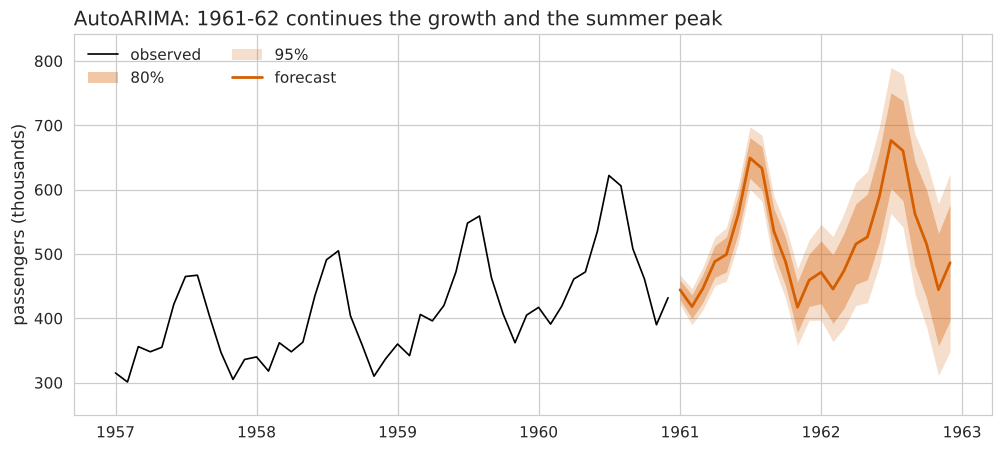

80% band width: 30k (month 1) -> 82k (month 12) -> 181k (month 24)
forecast 1961 total: 6,041k vs 1960 actual 5,714k


In [22]:
fc_plot = final_fc.rename(columns={c: c.replace(f"{MY_NAME}-", "") for c in final_fc.columns}
                         ).rename(columns={MY_NAME: "mean"})
P.fan_chart(df, fc_plot, history_tail=48, levels=(80, 95),
            title=f"{MY_NAME}: 1961-62 continues the growth and the summer peak")
plt.gca().set_ylabel("passengers (thousands)")
plt.savefig("figures/03_forecast.png", bbox_inches="tight")
plt.show()

w = final_fc[f"{MY_NAME}-hi-80"] - final_fc[f"{MY_NAME}-lo-80"]
print(f"80% band width: {w.iloc[0]:.0f}k (month 1) -> {w.iloc[11]:.0f}k (month 12) "
      f"-> {w.iloc[23]:.0f}k (month 24)")
print(f"forecast 1961 total: {final_fc[MY_NAME].iloc[:12].sum():,.0f}k vs 1960 actual "
      f"{df['y'].iloc[-12:].sum():,.0f}k")

**The forecast.** 1961 is forecast at 6.0 million passengers against 5.7
million in 1960 (+6%), with the summer peak and November low in place. The
80% band widens from 30 thousand in month 1 to 82 thousand in month 12 and
181 thousand by month 24. Read it with the coverage check in mind: in the
harness this band held about 70% of months, not 80%, so treat it as an
**optimistic** band, and more so the further traffic climbs.

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**The report is in [`report.md`](report.md)**, with the charts saved by this
notebook in `figures/`. Every number in it is printed by a cell above.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.

*Not attempted in this submission.*